# Ejercicio 4: Análisis estadístico de datos — ICA

**Tópicos Selectos en Aprendizaje Maquinal — TP N°1: Algoritmos para Reconocimiento de Patrones**

En este notebook se resuelve el Ejercicio 4 de la guía: se implementa el algoritmo **FastICA con aprendizaje deflacionario** y se lo utiliza para separar una mezcla de dos fuentes laplacianas, estudiando además qué ocurre cuando el modelo se aparta de sus hipótesis.

| Inciso | Consigna | Idea central |
|:--|:--|:--|
| **1** | Implementar FastICA con aprendizaje deflacionario | Maximizar la no gaussianidad de $\mathbf{w}^\top\mathbf{z}$ sobre datos blanqueados |
| **2a** | Gráfico de dispersión de cada etapa (fuentes, mezclas, blanqueadas, separadas) | Qué hace cada paso, geométricamente |
| **2b** | Estimar las matrices $\mathbf{P}$ y $\mathbf{D}$ | Ambigüedades de ICA: permutación y escala |
| **2c** | ¿$\mathbf{W}$ es la inversa de $\mathbf{A}$? | $\mathbf{W}=\mathbf{P}\mathbf{D}\mathbf{A}^{-1}$, no $\mathbf{A}^{-1}$ |
| **2d** | Efecto del ruido gaussiano aditivo | El modelo sin ruido deja de ser exacto |
| **2e** | Fuentes gaussianas (una, o ambas) | Se necesita no gaussianidad para separar |

**Contenido**

1. [Implementación de FastICA deflacionario](#1.-Implementación-de-FastICA-deflacionario)
2. [Separación de dos fuentes laplacianas](#2.-Separación-de-dos-fuentes-laplacianas)
3. [Conclusiones](#3.-Conclusiones)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import linear_sum_assignment
from sklearn.decomposition import FastICA as FastICA_sklearn      # solo para validar nuestra implementación

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

---
## 1. Implementación de FastICA deflacionario

> *Implemente el algoritmo de FastICA con aprendizaje deflacionario.*

### 1.1 Marco teórico

**El problema.** Se observan $n$ mezclas $\mathbf{x}=(x_1,\dots,x_n)^\top$ que son combinaciones lineales de $n$ **fuentes** $\mathbf{s}=(s_1,\dots,s_n)^\top$ desconocidas, estadísticamente independientes:

$$
\mathbf{x}=\mathbf{A}\mathbf{s},
$$

donde la **matriz de mezcla** $\mathbf{A}$ también es desconocida. El **Análisis de Componentes Independientes (ICA)** busca una **matriz de separación** $\mathbf{W}$ tal que $\mathbf{y}=\mathbf{W}\mathbf{x}$ recupere las fuentes, usando solo las mezclas y el supuesto de independencia. A diferencia de PCA (que solo descorrelaciona, usando estadísticos de segundo orden), ICA necesita **estadísticos de orden superior**, y por eso exige que las fuentes sean **no gaussianas**.

**Hipótesis y ambigüedades.**

- Las fuentes son independientes y **a lo sumo una** es gaussiana (si hubiera dos o más gaussianas el modelo no sería identificable; se verá en el inciso 2e).
- **Escala:** si se multiplica $s_i$ por $\alpha$ y la columna $i$ de $\mathbf{A}$ por $1/\alpha$, las mezclas no cambian. Las varianzas de las fuentes no se pueden determinar (se fijan a 1 por convención), ni tampoco su **signo**.
- **Orden:** el orden en que se numeran las fuentes es arbitrario.

Por lo tanto ICA recupera las fuentes solo salvo permutación y escala: $\mathbf{W}\mathbf{A}=\mathbf{P}\mathbf{D}$, con $\mathbf{P}$ una matriz de permutación y $\mathbf{D}$ una matriz diagonal (inciso 2b).

**Idea central: no gaussianidad.** Por el teorema del límite central (ejercicio 1.2), una combinación lineal de variables independientes es **más gaussiana** que cada una de ellas. Entonces, *buscar las proyecciones $y=\mathbf{w}^\top\mathbf{x}$ lo más no gaussianas posible* equivale a buscar las fuentes originales. La no gaussianidad se mide, por ejemplo, con la **curtosis** o con la **negentropía** $J(y)=H(y_{gauss})-H(y)$ (la entropía del ejercicio 1.3: la gaussiana es la de mayor entropía a igual varianza, así que $J\geq0$ y $J=0$ solo si $y$ es gaussiana). Una aproximación robusta es

$$
J(y)\propto\big[E\{G(y)\}-E\{G(\nu)\}\big]^2,\qquad \nu\sim\mathcal{N}(0,1),\qquad G(u)=\ln\cosh u,\quad g(u)=G'(u)=\tanh u.
$$

**Preprocesamiento.**

1. **Centrado:** restar la media de cada mezcla.
2. **Blanqueado:** transformar $\mathbf{z}=\mathbf{V}\mathbf{x}$ de modo que $E\{\mathbf{z}\mathbf{z}^\top\}=\mathbf{I}$. Con la descomposición de la covarianza $E\{\mathbf{x}\mathbf{x}^\top\}=\mathbf{E}\boldsymbol{\Lambda}\mathbf{E}^\top$ se toma $\mathbf{V}=\mathbf{E}\boldsymbol{\Lambda}^{-1/2}\mathbf{E}^\top$ (blanqueado simétrico o "ZCA"; también sirve $\boldsymbol{\Lambda}^{-1/2}\mathbf{E}^\top$). Después del blanqueado $\mathbf{z}=(\mathbf{V}\mathbf{A})\mathbf{s}$ y $\mathbf{V}\mathbf{A}$ resulta **ortogonal**, porque $\mathbf{I}=E\{\mathbf{z}\mathbf{z}^\top\}=(\mathbf{V}\mathbf{A})(\mathbf{V}\mathbf{A})^\top$ (las fuentes tienen varianza 1 por convención). Así, el problema se reduce a encontrar una **rotación**: de $n^2$ parámetros a estimar pasamos a $n(n-1)/2$.

**Iteración de punto fijo (FastICA).** Para un vector unitario $\mathbf{w}$, sobre los datos blanqueados:

$$
\mathbf{w}^{+}=E\{\mathbf{z}\,g(\mathbf{w}^\top\mathbf{z})\}-E\{g'(\mathbf{w}^\top\mathbf{z})\}\,\mathbf{w},\qquad \mathbf{w}\leftarrow\frac{\mathbf{w}^{+}}{\|\mathbf{w}^{+}\|}.
$$

Es una iteración de tipo Newton para maximizar la aproximación de negentropía (con convergencia al menos cuadrática). Se itera hasta que $\mathbf{w}$ deje de cambiar (salvo signo).

**Aprendizaje deflacionario.** Las componentes se estiman **una por una**. Para la $p$-ésima, tras cada iteración se **ortogonaliza** $\mathbf{w}_p$ respecto de las ya halladas (Gram–Schmidt):

$$
\mathbf{w}_p\leftarrow\mathbf{w}_p-\sum_{j<p}(\mathbf{w}_p^\top\mathbf{w}_j)\,\mathbf{w}_j,
$$

y se normaliza. Esto impide que dos vectores converjan a la misma fuente. (La alternativa *simétrica* estima todas a la vez y ortogonaliza la matriz entera.) La matriz de separación total es $\mathbf{W}=\mathbf{W}_{ica}\mathbf{V}$ y las fuentes estimadas $\mathbf{y}=\mathbf{W}\mathbf{x}_c$.

### 1.2 Implementación

Las señales se almacenan **por filas** ($n$ señales $\times$ $N$ muestras).

In [2]:
def centrar(X):
    '''Resta la media de cada señal (fila).'''
    return X - X.mean(axis=1, keepdims=True)


def blanquear(X):
    '''Blanqueado simétrico: z = V x con V = E Λ^{-1/2} E^T. Devuelve (Z, V) con cov(Z) = I.'''
    lam, E = np.linalg.eigh(np.cov(X))
    V = E @ np.diag(lam ** -0.5) @ E.T
    return V @ X, V


def fastica_deflacionario(Z, n_comp=None, max_iter=500, tol=1e-6, alpha=1.0, rng=None):
    '''
    FastICA con aprendizaje deflacionario sobre datos blanqueados Z (d x N), con g(u) = tanh(alpha u).
    Devuelve W_ica (n_comp x d) con vectores de norma 1 y ortogonales entre sí, y los diagnósticos de convergencia.
    '''
    rng = np.random.default_rng() if rng is None else rng
    d, N = Z.shape
    n_comp = d if n_comp is None else n_comp
    W = np.zeros((n_comp, d))
    n_iter, convergio = [], []

    for p in range(n_comp):
        w = rng.standard_normal(d)
        w /= np.linalg.norm(w)

        for it in range(1, max_iter + 1):
            u = w @ Z                                          # proyección w^T z (N,)
            g = np.tanh(alpha * u)
            g_prima = alpha * (1 - g ** 2)

            w_nuevo = (Z * g).mean(axis=1) - g_prima.mean() * w        # iteración de punto fijo
            if p > 0:                                                  # deflación: Gram-Schmidt contra las ya halladas
                w_nuevo -= W[:p].T @ (W[:p] @ w_nuevo)
            w_nuevo /= np.linalg.norm(w_nuevo)

            ok = abs(abs(w_nuevo @ w) - 1) < tol               # w y w_nuevo apuntan en la misma dirección (salvo signo)
            w = w_nuevo
            if ok:
                break

        W[p] = w
        n_iter.append(it)
        convergio.append(ok)
    return W, n_iter, convergio


def ica(X, rng, **kwargs):
    '''Pipeline completo: centrado -> blanqueado -> FastICA. Devuelve todas las etapas y la matriz W total.'''
    Xc = centrar(X)
    Xw, V = blanquear(Xc)
    W_ica, n_iter, conv = fastica_deflacionario(Xw, rng=rng, **kwargs)
    W = W_ica @ V                                              # W total: y = W x_c
    return dict(Xc=Xc, Xw=Xw, V=V, W_ica=W_ica, W=W, Y=W @ Xc, n_iter=n_iter, convergio=conv)

### 1.3 Herramientas para evaluar la separación

Como el resultado de ICA solo está definido salvo permutación, signo y escala, **no se puede comparar $\mathbf{y}$ con $\mathbf{s}$ directamente**. Se usan dos medidas que son invariantes a esas ambigüedades:

- **Índice de Amari** de la matriz global $\mathbf{G}=\mathbf{W}\mathbf{A}$. Si la separación es perfecta, $\mathbf{G}$ tiene un único elemento no nulo por fila y por columna ($\mathbf{G}=\mathbf{P}\mathbf{D}$). El índice mide cuánto se aparta de esa estructura:
$$
\text{Amari}(\mathbf{G})=\frac{1}{2n(n-1)}\left[\sum_{i}\Big(\sum_j\frac{|g_{ij}|}{\max_k|g_{ik}|}-1\Big)+\sum_{j}\Big(\sum_i\frac{|g_{ij}|}{\max_k|g_{kj}|}-1\Big)\right]\in[0,1],
$$
con $0$ para una separación perfecta.
- **Correlación absoluta** entre cada salida $y_i$ y la fuente que le corresponde (la asignación se obtiene maximizando la correlación total). Vale 1 si la fuente se recuperó exactamente.

In [3]:
def indice_amari(G):
    '''Índice de Amari normalizado: 0 = G es una matriz de permutación escalada (separación perfecta).'''
    A = np.abs(G)
    n = len(G)
    por_fila = (A / A.max(axis=1, keepdims=True)).sum(axis=1) - 1
    por_col = (A / A.max(axis=0, keepdims=True)).sum(axis=0) - 1
    return (por_fila.sum() + por_col.sum()) / (2 * n * (n - 1))


def correlacion_con_fuentes(Y, S):
    '''|correlación| de cada salida y_i con su fuente asignada (asignación óptima) y la fuente elegida.'''
    n = len(Y)
    C = np.abs(np.corrcoef(Y, S)[:n, n:])
    fila, col = linear_sum_assignment(-C)
    return C[fila, col], col


def estimar_P_D(G):
    '''
    Descompone G = P D (permutación x diagonal): en cada fila, el elemento de mayor módulo marca la posición
    del 1 de P y el valor del elemento diagonal de D correspondiente.
    '''
    n = len(G)
    P, d = np.zeros((n, n)), np.zeros(n)
    for i, j in enumerate(np.argmax(np.abs(G), axis=1)):
        P[i, j] = 1
        d[j] = G[i, j]
    return P, np.diag(d)

---
## 2. Separación de dos fuentes laplacianas

> *A partir de datos de dos mezclas, obtenidos mediante dos fuentes generadas ambas con distribución Laplaciana, y una matriz de mezcla aleatoria, utilice FastICA para lo siguiente:*
> *a) Para cada etapa (fuentes, mezclas, señales blanqueadas, señales separadas) dibuje un gráfico de dispersión de las variables. b) Luego de la separación, estime las matrices $\mathbf{P}$ y $\mathbf{D}$. c) ¿La matriz de separación $\mathbf{W}$ es la inversa de la matriz de mezcla $\mathbf{A}$ utilizada? d) ¿Cómo se afecta este resultado si agrega una componente de ruido gaussiano al modelo generativo? e) ¿Qué ocurre si una de las fuentes es gaussiana? ¿Y si ambas fuentes lo son?*

### 2.1 Generación de los datos

- **Fuentes:** dos señales independientes con distribución de **Laplace** (media 0 y parámetro de escala 1, o sea varianza $2$). La laplaciana es **supergaussiana**: tiene un pico más agudo y colas más pesadas que la gaussiana (exceso de curtosis $=3$).
- **Matriz de mezcla $\mathbf{A}$:** $2\times2$ aleatoria (elementos uniformes en $[-1,1]$). Se descartan las matrices mal condicionadas (para que el problema no sea numéricamente degenerado) y aquellas para las que, luego del blanqueado, las mezclas ya quedarían casi alineadas con los ejes: en ese caso el blanqueado por sí solo "separaría" las fuentes y el experimento no demostraría nada.
- **Mezclas:** $\mathbf{x}=\mathbf{A}\mathbf{s}$.

In [4]:
N = 5000
rng = np.random.default_rng(42)


def fuentes_laplace(N, rng, n=2):
    return rng.laplace(loc=0.0, scale=1.0, size=(n, N))          # varianza 2


def matriz_mezcla_aleatoria(rng, cond_max=6, ang_min=20):
    '''
    Matriz 2 x 2 con elementos U(-1, 1). Se descartan:
      - las mal condicionadas (cond >= cond_max);
      - aquellas en las que, tras el blanqueado simétrico, las mezclas quedan casi alineadas con los ejes
        (rotación residual a menos de ang_min grados de un eje): en ese caso el blanqueado por sí solo ya "separa"
        y el problema sería trivial. La rotación residual es la del factor polar de A.
    '''
    while True:
        A = rng.uniform(-1, 1, (2, 2))
        U, _, Vt = np.linalg.svd(A)
        R = U @ Vt                                              # factor de rotación de A
        ang = abs(np.degrees(np.arctan2(R[1, 0], R[0, 0]))) % 90
        if np.linalg.cond(A) < cond_max and ang_min <= ang <= 90 - ang_min:
            return A


S = fuentes_laplace(N, rng)
A = matriz_mezcla_aleatoria(rng)
X = A @ S

print("Matriz de mezcla A:\n", A)
print(f"\nNúmero de condición de A: {np.linalg.cond(A):.2f}")
_U, _s, _Vt = np.linalg.svd(A)
_R = _U @ _Vt
print(f"Valores singulares de A: {_s}")
print(f"Rotación residual tras el blanqueado simétrico (módulo 90°): {abs(np.degrees(np.arctan2(_R[1, 0], _R[0, 0]))) % 90:.1f}°")
print(f"Varianza de las fuentes (teórica = 2): {S.var(axis=1)}")

Matriz de mezcla A:
 [[-0.3924 -0.6857]
 [-0.2084  0.9587]]

Número de condición de A: 2.68
Valores singulares de A: [1.1804 0.4398]
Rotación residual tras el blanqueado simétrico (módulo 90°): 56.5°
Varianza de las fuentes (teórica = 2): [2.0017 2.0203]


In [5]:
resultado = ica(X, rng)
Xc, Xw, V, W_ica, W, Y = (resultado[k] for k in ["Xc", "Xw", "V", "W_ica", "W", "Y"])

print("Iteraciones hasta converger por componente:", resultado["n_iter"], "| convergió:", resultado["convergio"])
print("\nMatriz de blanqueo V:\n", V)
print("\nCovarianza de las señales blanqueadas (debe ser I):\n", np.cov(Xw))
print("\nW_ica (rotación sobre datos blanqueados):\n", W_ica)
print("W_ica W_ica^T = I:", np.allclose(W_ica @ W_ica.T, np.eye(2)))
print("\nMatriz de separación total W = W_ica V:\n", W)

Iteraciones hasta converger por componente: [3, 2] | convergió: [np.True_, np.True_]

Matriz de blanqueo V:
 [[1.2408 0.4867]
 [0.4867 0.9629]]

Covarianza de las señales blanqueadas (debe ser I):
 [[1. 0.]
 [0. 1.]]

W_ica (rotación sobre datos blanqueados):
 [[-0.5368  0.8437]
 [-0.8437 -0.5368]]
W_ica W_ica^T = I: True

Matriz de separación total W = W_ica V:
 [[-0.2553  0.5512]
 [-1.3081 -0.9275]]


### 2.2 a) Gráficos de dispersión de cada etapa

Se grafican los pares de variables $(x_1,x_2)$ en cada etapa. En el gráfico de las mezclas se dibujan además las **columnas de $\mathbf{A}$** (flechas), que son las direcciones hacia las que cada fuente "estira" la nube.

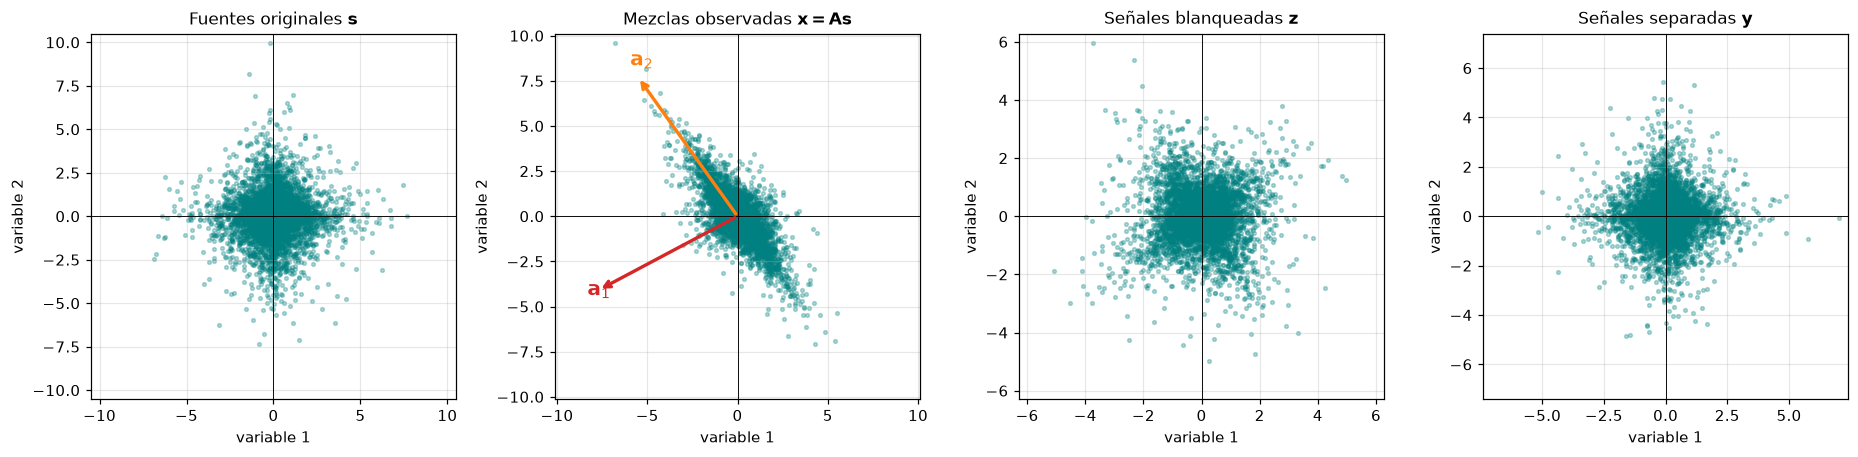

In [6]:
def graficar_etapas(S, X, Xw, Y, A, titulo=None):
    fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
    etapas = [(S, "Fuentes originales $\\mathbf{s}$"), (X, "Mezclas observadas $\\mathbf{x}=\\mathbf{A}\\mathbf{s}$"),
              (Xw, "Señales blanqueadas $\\mathbf{z}$"), (Y, "Señales separadas $\\mathbf{y}$")]
    for ax, (datos, nombre) in zip(axes, etapas):
        ax.scatter(datos[0], datos[1], s=6, alpha=0.3, color="teal")
        ax.set_title(nombre, fontsize=11)
        ax.set_aspect("equal")
        lim = 1.05 * np.abs(datos).max()
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
        ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
    # Direcciones de las columnas de A sobre las mezclas
    for k, color in enumerate(["tab:red", "tab:orange"]):
        escala = 0.8 * np.abs(X).max() / np.abs(A[:, k]).max()
        axes[1].annotate("", xy=escala * A[:, k], xytext=(0, 0),
                         arrowprops=dict(arrowstyle="->", color=color, lw=2.2))
        axes[1].text(*(1.08 * escala * A[:, k]), f"$\\mathbf{{a}}_{k + 1}$", color=color, fontsize=13)
    for ax in axes:
        ax.set_xlabel("variable 1"); ax.set_ylabel("variable 2")
    if titulo:
        fig.suptitle(titulo, y=1.03, fontsize=13)
    plt.tight_layout()
    plt.show()


graficar_etapas(S, X, Xw, Y, A)

Además de la inspección visual, se cuantifica la "no gaussianidad" de cada etapa con el **exceso de curtosis** (vale 0 para una gaussiana y 3 para una laplaciana). Debería ser alto en las fuentes, bajo en las mezclas (el TLC las vuelve más gaussianas) y volver a ser alto en las señales separadas.

In [7]:
print(f"{'Etapa':<22} | {'señal 1':>8} | {'señal 2':>8}")
for nombre, datos in [("Fuentes s", S), ("Mezclas x", X), ("Blanqueadas z", Xw), ("Separadas y", Y)]:
    k = stats.kurtosis(datos, axis=1)
    print(f"{nombre:<22} | {k[0]:8.2f} | {k[1]:8.2f}")
print("Gaussiana = 0, Laplace = 3 (valor teórico)")

Etapa                  |  señal 1 |  señal 2
Fuentes s              |     2.91 |     3.08
Mezclas x              |     1.75 |     2.89
Blanqueadas z          |     1.61 |     1.80
Separadas y            |     3.09 |     2.91
Gaussiana = 0, Laplace = 3 (valor teórico)


**Observaciones.**

- **Fuentes.** Al ser laplacianas e independientes, la nube tiene forma de "estrella" o rombo con puntas sobre los ejes: es *supergaussiana* (pico agudo y colas pesadas), y cuando una fuente es grande la otra suele ser pequeña.
- **Mezclas.** La transformación lineal $\mathbf{A}$ deforma y rota la nube: ahora las puntas apuntan en las direcciones de las columnas $\mathbf{a}_1$ y $\mathbf{a}_2$ (las flechas), que ya no son ortogonales. Las variables observadas están correlacionadas.
- **Blanqueado.** Elimina la correlación y normaliza las varianzas (covarianza igual a $\mathbf{I}$), pero **no alcanza para separar**: la estructura de puntas sigue presente, ahora con dos direcciones **ortogonales** pero rotadas respecto de los ejes (en este caso unos $56^\circ$ de rotación residual). Con estadísticos de segundo orden no hay nada más que hacer: cualquier rotación de datos blanqueados seguiría teniendo covarianza $\mathbf{I}$. Por eso PCA, que solo usa segundo orden, no puede separar las fuentes.
- **Separación.** FastICA encuentra la rotación que alinea las puntas con los ejes, y la nube recupera la forma de la de las fuentes (con otra escala: las salidas tienen varianza 1, las fuentes 2).
- **Curtosis.** Las fuentes y las salidas separadas tienen curtosis ($\approx3$, la teórica de la laplaciana). En cambio, las mezclas y sobre todo las señales blanqueadas son **menos no gaussianas** (la curtosis baja a $\approx1.6$ a $1.8$ en las blanqueadas, que combinan las dos fuentes con pesos parecidos): es el TLC en acción, y justifica el principio de FastICA de buscar las proyecciones más no gaussianas. (La segunda mezcla conserva una curtosis alta, $\approx2.9$, porque la segunda fila de $\mathbf{A}$ está dominada por $s_2$.)

### 2.3 b) Estimación de las matrices $\mathbf{P}$ y $\mathbf{D}$

Si la separación fue exitosa, la matriz global $\mathbf{G}=\mathbf{W}\mathbf{A}$ (que combina la mezcla y la separación) debe ser una **matriz de permutación escalada**:

$$
\mathbf{G}=\mathbf{W}\mathbf{A}=\mathbf{P}\,\mathbf{D}\quad\Longleftrightarrow\quad \mathbf{W}=\mathbf{P}\,\mathbf{D}\,\mathbf{A}^{-1},
$$

donde $\mathbf{P}$ (permutación) refleja la **ambigüedad de orden** y $\mathbf{D}$ (diagonal) la **ambigüedad de escala y signo**. (Escribir $\mathbf{P}\mathbf{D}$ o $\mathbf{D}'\mathbf{P}$ es equivalente: $\mathbf{P}\mathbf{D}=(\mathbf{P}\mathbf{D}\mathbf{P}^\top)\mathbf{P}$ con $\mathbf{D}'=\mathbf{P}\mathbf{D}\mathbf{P}^\top$ también diagonal.)

**Valor esperado de $\mathbf{D}$.** FastICA impone varianza unitaria en las salidas ($\mathbf{W}_{ica}$ es una rotación de datos blanqueados). Como $y_i=D_{jj}\,s_j$ para la fuente $j$ asignada, debe ser

$$
|D_{jj}|=\frac{1}{\sigma_{s_j}}=\frac{1}{\sqrt{2}}\approx0.707
$$

(con varianza de la fuente laplaciana igual a 2), y el signo es arbitrario.

In [8]:
G = W @ A
P, D = estimar_P_D(G)

print("G = W A  (matriz global):\n", G)
print("\nP (permutación estimada):\n", P)
print("\nD (escalas estimadas):\n", D)
print("\n||G - P D||  =", np.linalg.norm(G - P @ D).round(4), " (residuo; debería ser ~ 0)")
print("Índice de Amari de G:", round(indice_amari(G), 4), "| solo con el blanqueado (W_ica = I):", round(indice_amari(V @ A), 4))

# Valor esperado de |D|: 1/desvío de la fuente correspondiente
sigma_fuentes = S.std(axis=1, ddof=1)
j_asignada = np.argmax(P, axis=1)                    # fuente j que corresponde a cada salida i
print("\n|D_jj| estimado        :", np.abs(np.diag(D)))
print("1/σ_s esperado          :", 1 / sigma_fuentes)

G = W A  (matriz global):
 [[-0.0147  0.7035]
 [ 0.7066  0.0078]]

P (permutación estimada):
 [[0. 1.]
 [1. 0.]]

D (escalas estimadas):
 [[0.7066 0.    ]
 [0.     0.7035]]

||G - P D||  = 0.0167  (residuo; debería ser ~ 0)
Índice de Amari de G: 0.016 | solo con el blanqueado (W_ica = I): 0.6588

|D_jj| estimado        : [0.7066 0.7035]
1/σ_s esperado          : [0.7067 0.7035]


### 2.4 c) ¿$\mathbf{W}$ es la inversa de $\mathbf{A}$?

**No exactamente.** Si $\mathbf{W}$ fuera $\mathbf{A}^{-1}$, entonces $\mathbf{G}=\mathbf{W}\mathbf{A}$ sería la identidad. En cambio, $\mathbf{W}$ es la inversa **salvo permutación y escala**: $\mathbf{W}=\mathbf{P}\mathbf{D}\mathbf{A}^{-1}$. Se verifica numéricamente.

In [9]:
A_inv = np.linalg.inv(A)
print("A^{-1}:\n", A_inv)
print("\nW estimada:\n", W)
print("\nG = W A  (distinta de la identidad):\n", G)

# W corregida por permutación y escala: D^{-1} P^T W  debería ser A^{-1}
W_corregida = np.linalg.inv(D) @ P.T @ W
print("\nD^-1 P^T W (debería ser A^{-1}):\n", W_corregida)
print("Error relativo ||D^-1 P^T W - A^-1|| / ||A^-1|| =", (np.linalg.norm(W_corregida - A_inv) / np.linalg.norm(A_inv)).round(4))

# De la misma manera, A se recupera salvo permutación y escala: W^{-1} = A D^{-1} P^T
print("\nW^{-1} (estimación de A):\n", np.linalg.inv(W))
print("A D^{-1} P^T (lo que predice la teoría):\n", A @ np.linalg.inv(D) @ P.T)

A^{-1}:
 [[-1.8468 -1.321 ]
 [-0.4015  0.7559]]

W estimada:
 [[-0.2553  0.5512]
 [-1.3081 -0.9275]]

G = W A  (distinta de la identidad):
 [[-0.0147  0.7035]
 [ 0.7066  0.0078]]

D^-1 P^T W (debería ser A^{-1}):
 [[-1.8512 -1.3126]
 [-0.3629  0.7835]]
Error relativo ||D^-1 P^T W - A^-1|| / ||A^-1|| = 0.0199

W^{-1} (estimación de A):
 [[-0.9684 -0.5754]
 [ 1.3658 -0.2666]]
A D^{-1} P^T (lo que predice la teoría):
 [[-0.9748 -0.5553]
 [ 1.3628 -0.295 ]]


**Las fuentes se recuperan salvo orden, signo y escala.** El siguiente gráfico representa cada salida $y_i$ frente a la fuente $s_j$ que le corresponde: debería ser una recta de pendiente $D_{jj}=\pm1/\sigma_{s_j}$ (distinta de 1 en general).

Fuente asignada a cada salida: [1 0] | |correlación|: [0.9998 0.9999]


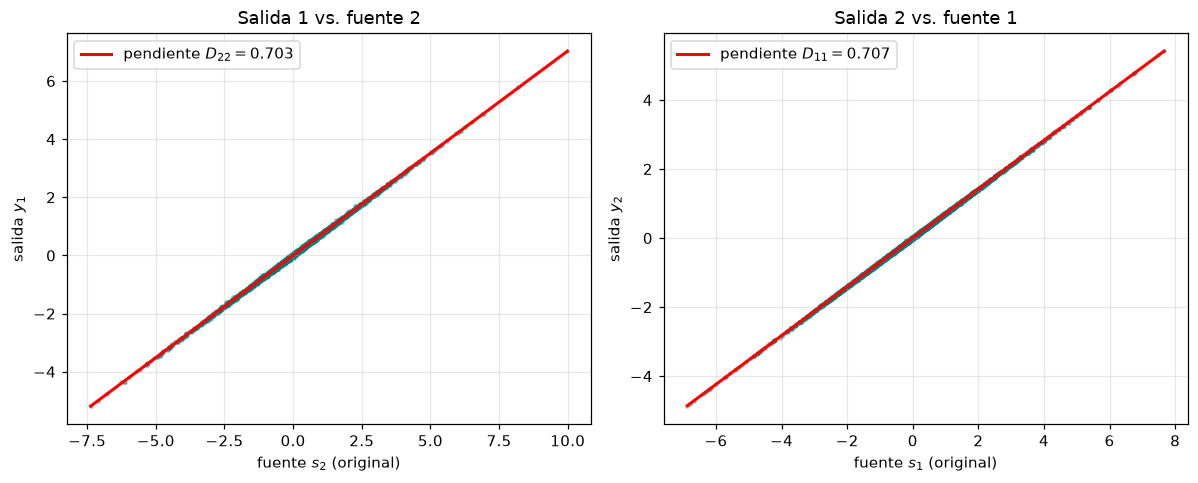

In [10]:
corr, col = correlacion_con_fuentes(Y, S)
print("Fuente asignada a cada salida:", col, "| |correlación|:", corr.round(5))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for i, ax in enumerate(axes):
    j = col[i]
    ax.scatter(S[j], Y[i], s=5, alpha=0.3, color="teal")
    xs = np.array([S[j].min(), S[j].max()])
    ax.plot(xs, D[j, j] * xs, "r-", lw=2, label=f"pendiente $D_{{{j + 1}{j + 1}}}={D[j, j]:.3f}$")
    ax.set_xlabel(f"fuente $s_{j + 1}$ (original)"); ax.set_ylabel(f"salida $y_{i + 1}$")
    ax.set_title(f"Salida {i + 1} vs. fuente {j + 1}")
    ax.legend()
plt.tight_layout()
plt.show()

#### Las ambigüedades en acción: varias inicializaciones

FastICA arranca de un $\mathbf{w}$ aleatorio. Si se repite el algoritmo sobre **los mismos datos** con distintas semillas, la separación es igual de buena, pero $\mathbf{P}$ y los signos de $\mathbf{D}$ cambian de una corrida a otra, mostrando que el orden y el signo son arbitrarios.

In [11]:
print(f"{'corrida':>7} | {'permutación (fuente de y1, y2)':<30} | {'diag(D)':<20} | Amari")
for k in range(8):
    r = ica(X, np.random.default_rng(100 + k))
    Gk = r["W"] @ A
    Pk, Dk = estimar_P_D(Gk)
    perm = tuple(int(j) + 1 for j in np.argmax(Pk, axis=1))
    print(f"{k + 1:>7} | {str(perm):<30} | {np.array2string(np.diag(Dk), precision=3):<20} | {indice_amari(Gk):.4f}")

corrida | permutación (fuente de y1, y2) | diag(D)              | Amari
      1 | (2, 1)                         | [-0.707  0.703]      | 0.0160
      2 | (1, 2)                         | [-0.707  0.704]      | 0.0048
      3 | (1, 2)                         | [-0.707 -0.704]      | 0.0048
      4 | (2, 1)                         | [-0.707  0.703]      | 0.0160
      5 | (1, 2)                         | [0.707 0.704]        | 0.0048
      6 | (2, 1)                         | [-0.707  0.703]      | 0.0160
      7 | (1, 2)                         | [-0.707 -0.704]      | 0.0048
      8 | (2, 1)                         | [-0.707  0.703]      | 0.0160


**Observaciones.**

- **b) $\mathbf{P}$ y $\mathbf{D}$.** La matriz global resulta $\mathbf{G}\approx\begin{pmatrix}0&0.704\\0.707&0\end{pmatrix}$, es decir una **permutación escalada**: $\mathbf{P}$ intercambia las dos salidas respecto del orden de las fuentes y $\mathbf{D}=\mathrm{diag}(0.707,\,0.704)$. Los valores de $\mathbf{D}$ coinciden con lo previsto, $1/\sigma_{s_j}\approx0.707$ (las salidas tienen varianza unitaria y las fuentes varianza 2). El residuo $\|\mathbf{G}-\mathbf{P}\mathbf{D}\|\approx0.02$ y el índice de Amari de $0.016$ no son exactamente cero por el tamaño finito de la muestra ($N=5000$). Como referencia, usar solo el blanqueado (sin ICA) da un Amari de $0.66$.
- **c) ¿$\mathbf{W}=\mathbf{A}^{-1}$?** **No.** Si lo fuera, $\mathbf{G}$ sería la identidad. Lo que vale es $\mathbf{W}=\mathbf{P}\mathbf{D}\mathbf{A}^{-1}$: $\mathbf{W}$ es la inversa de $\mathbf{A}$ **salvo permutación y escala**. Corrigiendo con $\mathbf{D}^{-1}\mathbf{P}^\top\mathbf{W}$ se recupera $\mathbf{A}^{-1}$ con un error relativo de ~2 %. Análogamente $\mathbf{W}^{-1}=\mathbf{A}\mathbf{D}^{-1}\mathbf{P}^\top$ estima las columnas de $\mathbf{A}$ pero en otro orden y con otra escala. Esto no es una falla del algoritmo: es una **ambigüedad intrínseca** del modelo (cualquier $\mathbf{P}$ y $\mathbf{D}$ dan mezclas idénticas), como lo muestra la tabla de corridas, en la que el orden y el signo cambian según la inicialización, mientras que la calidad de la separación (Amari) se mantiene.
- **Efecto del orden de deflación.** Los valores del Amari de la tabla toman solo dos valores (0.005 o 0.016) según qué fuente se encuentra primero. Es esperable en la deflación: solo la primera componente se obtiene optimizando libremente el contraste, y la última queda fijada por la ortogonalidad con las anteriores (en 2D, el complemento ortogonal), por lo que hereda su error de estimación. La diferencia es pequeña, pero muestra que los errores se acumulan.
- **Validación.** La implementación coincide con `scikit-learn`: las correlaciones absolutas entre ambas salidas forman una matriz identidad (1.0 en la diagonal, ~0 fuera) y el índice de Amari es el mismo.

### 2.5 Validación contra `scikit-learn`

Como chequeo adicional de la implementación se compara con `sklearn.decomposition.FastICA` (también con algoritmo deflacionario y no linealidad $\log\cosh$). Dado que las señales solo están definidas salvo orden y signo, se compara la **matriz de correlación absoluta** entre las salidas de ambas implementaciones: debe ser una matriz de permutación.

In [12]:
sk_ica = FastICA_sklearn(n_components=2, algorithm="deflation", whiten="unit-variance", fun="logcosh",
                         random_state=0, max_iter=1000, tol=1e-6)
Y_sk = sk_ica.fit_transform(X.T).T

C = np.abs(np.corrcoef(Y, Y_sk)[:2, 2:])
print("|correlación| entre nuestras salidas (filas) y las de sklearn (columnas):\n", C)
G_sk = sk_ica.components_ @ A                       # components_ ya es la matriz de separación total (x -> y)
print("Índice de Amari - sklearn:", round(indice_amari(G_sk), 4), "| propio:", round(indice_amari(G), 4))

|correlación| entre nuestras salidas (filas) y las de sklearn (columnas):
 [[1.     0.0001]
 [0.0001 1.    ]]
Índice de Amari - sklearn: 0.0159 | propio: 0.016


### 2.6 d) Efecto del ruido gaussiano aditivo

Se agrega al modelo generativo una componente de ruido gaussiano independiente de las fuentes:

$$
\mathbf{x}=\mathbf{A}\mathbf{s}+\mathbf{n},\qquad \mathbf{n}\sim\mathcal{N}(\mathbf{0},\sigma_n^2\mathbf{I}).
$$

**Por qué afecta a ICA (análisis).**

1. El modelo estimado por FastICA es *sin ruido*: supone $\mathbf{x}=\mathbf{A}\mathbf{s}$ con $\mathbf{A}$ cuadrada e invertible. El ruido no puede "separarse" porque ya no hay una matriz $\mathbf{W}$ que recupere las fuentes de forma exacta: $\mathbf{W}\mathbf{x}=\mathbf{W}\mathbf{A}\mathbf{s}+\mathbf{W}\mathbf{n}$ y el término $\mathbf{W}\mathbf{n}$ **contamina** cualquier salida, incluso con $\mathbf{W}=\mathbf{A}^{-1}$ (donde además $\mathbf{A}^{-1}$ amplifica el ruido si $\mathbf{A}$ está mal condicionada).
2. **El blanqueado se deteriora.** Ahora $\mathrm{Cov}(\mathbf{x})=\mathbf{A}\mathbf{A}^\top\sigma_s^2+\sigma_n^2\mathbf{I}$. Al blanquear $\mathbf{x}$, la parte de señal $\mathbf{V}\mathbf{A}\mathbf{s}$ ya no tiene covarianza identidad ($\mathrm{Cov}(\mathbf{V}\mathbf{A}\mathbf{s})=\mathbf{I}-\sigma_n^2\mathbf{V}\mathbf{V}^\top$), de modo que $\mathbf{V}\mathbf{A}$ **deja de ser ortogonal**. Pero FastICA justamente supone que lo es y busca solo una rotación: el resultado queda **sesgado**.
3. **Se reduce la no gaussianidad.** La suma de una fuente laplaciana más ruido gaussiano es *más gaussiana* que la fuente sola (otra vez el TLC), lo que dificulta la detección por negentropía.

**Experimento.** Se barre la desviación estándar $\sigma_n$ del ruido y se mide el desempeño de la separación (índice de Amari y correlación con las fuentes) promediando sobre $R=40$ repeticiones (nuevas fuentes y ruido en cada una, misma $\mathbf{A}$). Se informa también la **relación señal-ruido** de las mezclas, $\text{SNR}=10\log_{10}\dfrac{\overline{\mathrm{Var}(\mathbf{A}\mathbf{s})}}{\sigma_n^2}$.

In [13]:
def experimento(generar, sigma_n, R, rng):
    '''Repite R veces la separación. generar(rng) -> (S, A). Devuelve arrays con Amari y correlación media por corrida.'''
    amari, corr, base = [], [], []
    for _ in range(R):
        S_, A_ = generar(rng)
        X_ = A_ @ S_ + sigma_n * rng.standard_normal(S_.shape)
        r = ica(X_, rng)
        amari.append(indice_amari(r["W"] @ A_))
        base.append(indice_amari(r["V"] @ A_))                 # línea base: solo blanqueado (sin ICA)
        corr.append(correlacion_con_fuentes(r["Y"], S_)[0].mean())
    return np.array(amari), np.array(corr), np.array(base)


def snr_db(A_, S_, sigma_n):
    return np.inf if sigma_n == 0 else 10 * np.log10(np.var(A_ @ S_, axis=1).mean() / sigma_n ** 2)


def snr_debil(sigma_n):
    '''SNR en la dirección principal más débil de las mezclas (valor singular mínimo de A, fuentes de varianza 2).'''
    return np.inf if sigma_n == 0 else 10 * np.log10(2 * np.linalg.svd(A, compute_uv=False)[-1] ** 2 / sigma_n ** 2)


def corr_oraculo(sigma_n):
    '''
    |Correlación| media que lograría un separador *perfecto* W = A^{-1} en presencia de ruido: la salida i es
    s_i + (A^{-1} n)_i, con varianza de ruido sigma_n^2 ||fila_i(A^{-1})||^2 frente a Var(s_i) = 2.
    Es una cota superior para cualquier método lineal: el ruido que atraviesa W no se puede eliminar.
    '''
    norma2 = np.linalg.norm(np.linalg.inv(A), axis=1) ** 2
    return np.mean(1 / np.sqrt(1 + sigma_n ** 2 * norma2 / 2))


generar_laplace = lambda rng_: (fuentes_laplace(N, rng_), A)       # misma A, nuevas fuentes

sigmas = [0.0, 0.1, 0.25, 0.5, 1.0, 2.0, 4.0]
rng_ruido = np.random.default_rng(7)
res_ruido = {s: experimento(generar_laplace, s, 40, rng_ruido) for s in sigmas}

print(f"{'σ_n':>5} | {'SNR (dB)':>8} | {'SNR dir. débil':>13} | {'Amari (media ± desvío)':>22} | {'|corr| media ± desvío':>21} | |corr| oráculo | Amari solo blanq.")
for s in sigmas:
    am, co, base = res_ruido[s]
    print(f"{s:>5} | {snr_db(A, S, s):8.1f} | {snr_debil(s):13.1f} | {am.mean():8.4f} ± {am.std():.4f} | {co.mean():8.4f} ± {co.std():.4f} | {corr_oraculo(s):.4f} | {base.mean():.4f}")

  σ_n | SNR (dB) | SNR dir. débil | Amari (media ± desvío) | |corr| media ± desvío | |corr| oráculo | Amari solo blanq.
  0.0 |      inf |           inf |   0.0211 ± 0.0124 |   0.9997 ± 0.0003 | 1.0000 | 0.6622
  0.1 |     22.0 |          15.9 |   0.0175 ± 0.0115 |   0.9925 ± 0.0003 | 0.9928 | 0.6614
 0.25 |     14.1 |           7.9 |   0.0202 ± 0.0140 |   0.9582 ± 0.0013 | 0.9584 | 0.6620
  0.5 |      8.1 |           1.9 |   0.0319 ± 0.0320 |   0.8673 ± 0.0041 | 0.8685 | 0.6676
  1.0 |      2.0 |          -4.1 |   0.0522 ± 0.0361 |   0.6906 ± 0.0062 | 0.6921 | 0.6553
  2.0 |     -4.0 |         -10.1 |   0.1231 ± 0.1026 |   0.4655 ± 0.0108 | 0.4671 | 0.5664
  4.0 |    -10.0 |         -16.2 |   0.4094 ± 0.1671 |   0.2407 ± 0.0226 | 0.2678 | 0.5260


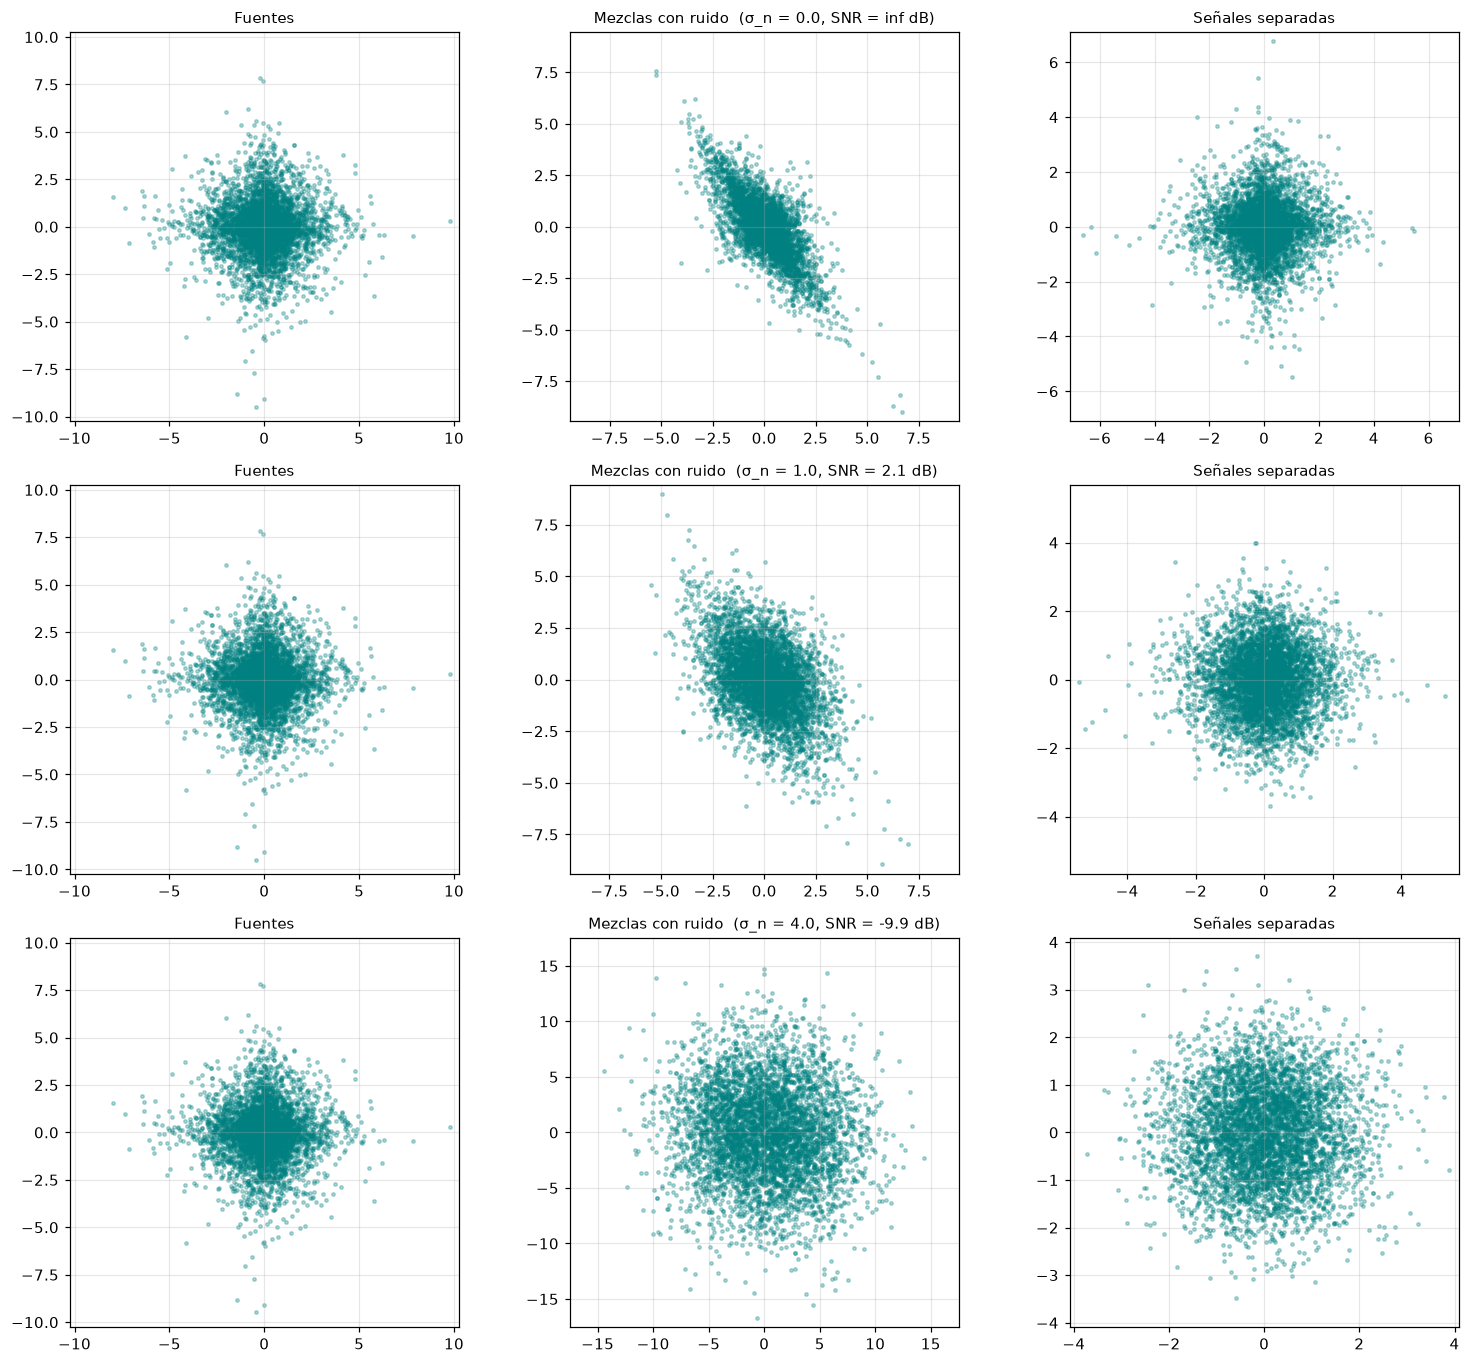

In [14]:
# --- Dispersión de las mezclas con ruido y de las salidas, para tres niveles de ruido ---
niveles = [0.0, 1.0, 4.0]
fig, axes = plt.subplots(3, 3, figsize=(14, 12.5))
for k, s in enumerate(niveles):
    r_ = np.random.default_rng(3)
    S_ = fuentes_laplace(N, r_)
    X_ = A @ S_ + s * r_.standard_normal(S_.shape)
    res = ica(X_, r_)
    for ax, datos, nombre in zip(axes[k], [S_, X_, res["Y"]], ["Fuentes", "Mezclas con ruido", "Señales separadas"]):
        ax.scatter(datos[0], datos[1], s=5, alpha=0.3, color="teal")
        lim = 1.05 * np.abs(datos).max()
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
        ax.set_title(f"{nombre}" + (f"  (σ_n = {s}, SNR = {snr_db(A, S_, s):.1f} dB)" if nombre == "Mezclas con ruido" else ""),
                     fontsize=10)
plt.tight_layout()
plt.show()

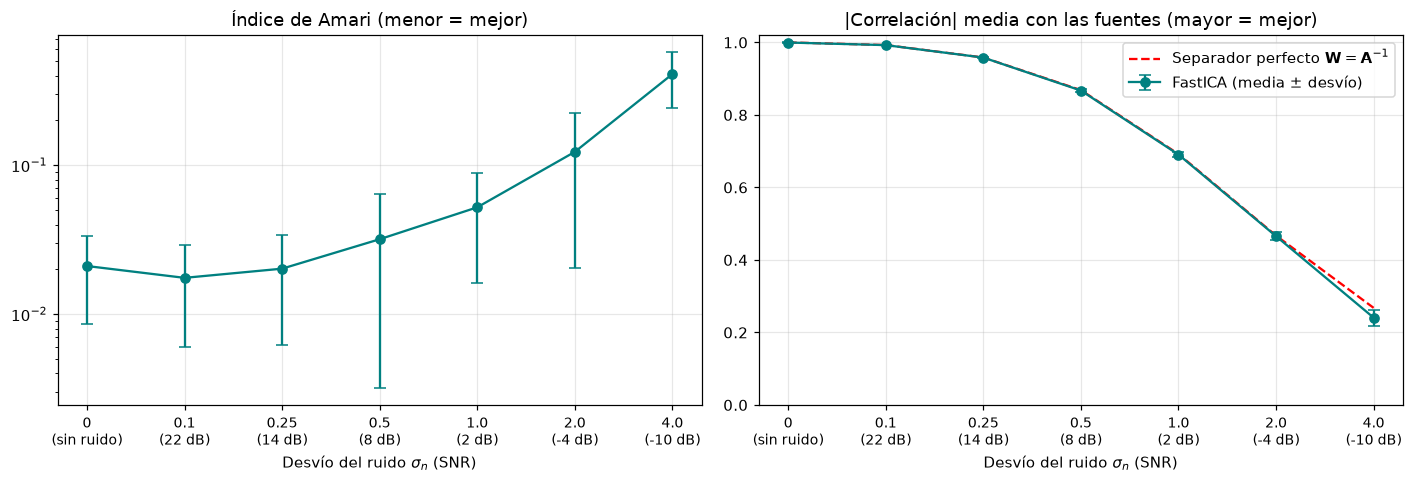

In [15]:
# --- Desempeño de la separación en función del ruido ---
x_plot = np.arange(len(sigmas))
etiquetas = [f"{s}\n({snr_db(A, S, s):.0f} dB)" if s > 0 else "0\n(sin ruido)" for s in sigmas]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, idx, nombre in [(ax1, 0, "Índice de Amari (menor = mejor)"), (ax2, 1, "|Correlación| media con las fuentes (mayor = mejor)")]:
    medias = [res_ruido[s][idx].mean() for s in sigmas]
    desvios = [res_ruido[s][idx].std() for s in sigmas]
    medias, desvios = np.array(medias), np.array(desvios)
    inferior = np.minimum(desvios, 0.9 * medias)             # evita barras negativas en escala logarítmica
    ax.errorbar(x_plot, medias, yerr=[inferior, desvios], fmt="o-", capsize=4, color="teal", label="FastICA (media ± desvío)")
    if idx == 1:
        ax.plot(x_plot, [corr_oraculo(s) for s in sigmas], "r--", label="Separador perfecto $\\mathbf{W}=\\mathbf{A}^{-1}$")
        ax.legend()
    ax.set_xticks(x_plot); ax.set_xticklabels(etiquetas, fontsize=9)
    ax.set_xlabel("Desvío del ruido $\\sigma_n$ (SNR)"); ax.set_title(nombre)
ax1.set_yscale("log")
ax2.set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

**Observaciones.**

- **Separación (dirección de $\mathbf{W}$).** El índice de Amari es muy robusto a ruido moderado: se mantiene alrededor de $0.02$ hasta una SNR de ~14 dB, y recién sube de forma apreciable con SNR de unos 2 dB ($0.05$), $-4$ dB ($0.12$) y $-10$ dB ($0.41$, cerca del azar). Es decir, $\mathbf{W}\mathbf{A}$ se aparta de $\mathbf{P}\mathbf{D}$ cada vez más: FastICA estima una $\mathbf{W}$ **sesgada**, porque el blanqueado deja de entregar una mezcla ortogonal (la covarianza de las mezclas incluye ahora el ruido) y porque la no gaussianidad de las fuentes queda diluida por el ruido gaussiano.
- **Calidad de las señales recuperadas.** La correlación de cada salida con su fuente cae mucho antes que el Amari: $0.999$ sin ruido, $0.96$ con 14 dB, $0.87$ con 8 dB, $0.69$ con 2 dB y $0.24$ con $-10$ dB. La causa principal **no es un error de FastICA** sino que el ruido atraviesa la matriz de separación: $\mathbf{y}=\mathbf{W}\mathbf{A}\mathbf{s}+\mathbf{W}\mathbf{n}$. Lo confirma la curva del separador perfecto $\mathbf{W}=\mathbf{A}^{-1}$ (calculada analíticamente), que es una cota superior para cualquier método lineal y que FastICA casi iguala en todo el rango (por ejemplo $0.4655$ frente a $0.4671$ con $\sigma_n=2$); solo con ruido muy alto ($\sigma_n=4$) queda algo por debajo ($0.24$ vs. $0.27$), donde el sesgo de $\mathbf{W}$ ya es grande.
- **Papel del condicionamiento de $\mathbf{A}$.** $\mathbf{A}^{-1}$ amplifica el ruido en la dirección en que $\mathbf{A}$ es más débil. Por eso la SNR en esa dirección (columna "SNR dir. débil") es unos 6 dB peor que la SNR promedio, y se pierde calidad antes de lo que sugiere la SNR global.
- **En los gráficos** se ve cómo las mezclas con ruido pierden la forma alargada original y con $-10$ dB resultan casi esféricas, y cómo las señales separadas dejan de mostrar las puntas características de la laplaciana (cada salida es ahora la fuente más una componente gaussiana).
- **Conclusión del inciso.** Con ruido, $\mathbf{W}$ **no** es $\mathbf{P}\mathbf{D}\mathbf{A}^{-1}$ (ni siquiera aproximadamente cuando el ruido es grande) y las salidas ya no son las fuentes, sino las fuentes contaminadas. Para ruido apreciable hacen falta métodos que lo modelen explícitamente (ICA con ruido, *denoising*), o aprovechar más mezclas que fuentes (reducción de dimensión con PCA) para promediar el ruido.

### 2.7 e) Fuentes gaussianas

**Análisis.** ICA identifica las fuentes gracias a su **no gaussianidad**. La razón profunda es que la gaussiana multivariada está completamente determinada por la media y la covarianza (estadísticos de segundo orden), y una gaussiana con covarianza $\mathbf{I}$ es **invariante a rotaciones**:

- Si $\mathbf{z}\sim\mathcal{N}(\mathbf{0},\mathbf{I})$, entonces $\mathbf{R}\mathbf{z}\sim\mathcal{N}(\mathbf{0},\mathbf{I})$ para cualquier rotación $\mathbf{R}$, con componentes independientes.
- Después del blanqueado, ICA solo debe encontrar una rotación. Si **dos fuentes son gaussianas**, los datos blanqueados son una gaussiana esférica, y **cualquier** rotación produce salidas igualmente descorrelacionadas e independientes: no hay una rotación "correcta" que elegir. La separación es **imposible** (el modelo no es identificable).
- Con **una sola fuente gaussiana** y las demás no gaussianas el modelo *sí* es identificable: las fuentes no gaussianas se detectan por su no gaussianidad y la gaussiana queda como el complemento ortogonal. Lo que no se puede identificar es más de una componente gaussiana.

**Experimento.** Se comparan tres escenarios (las fuentes gaussianas se toman con varianza $2$, igual que la laplaciana, para que las escalas sean comparables):

| Caso | Fuentes |
|:--|:--|
| **Referencia** | Laplace + Laplace |
| **(i)** | Laplace + Gaussiana |
| **(ii)** | Gaussiana + Gaussiana |

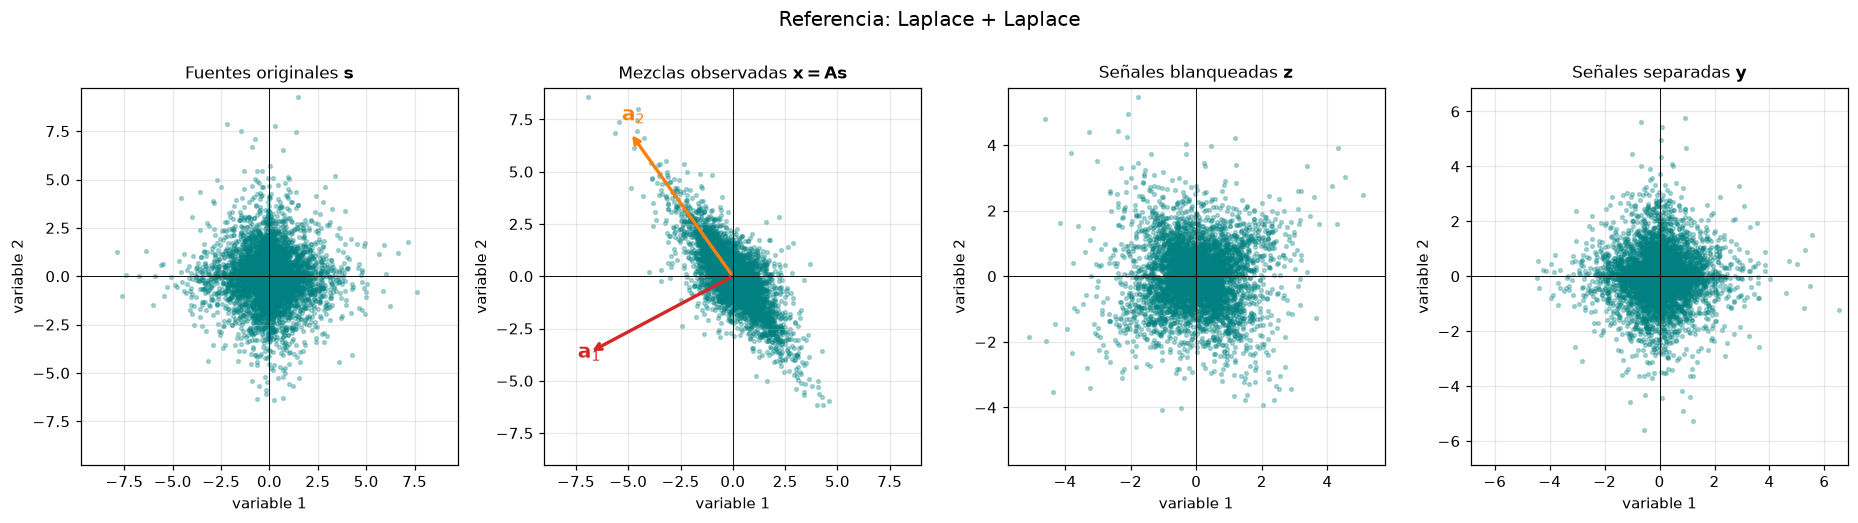

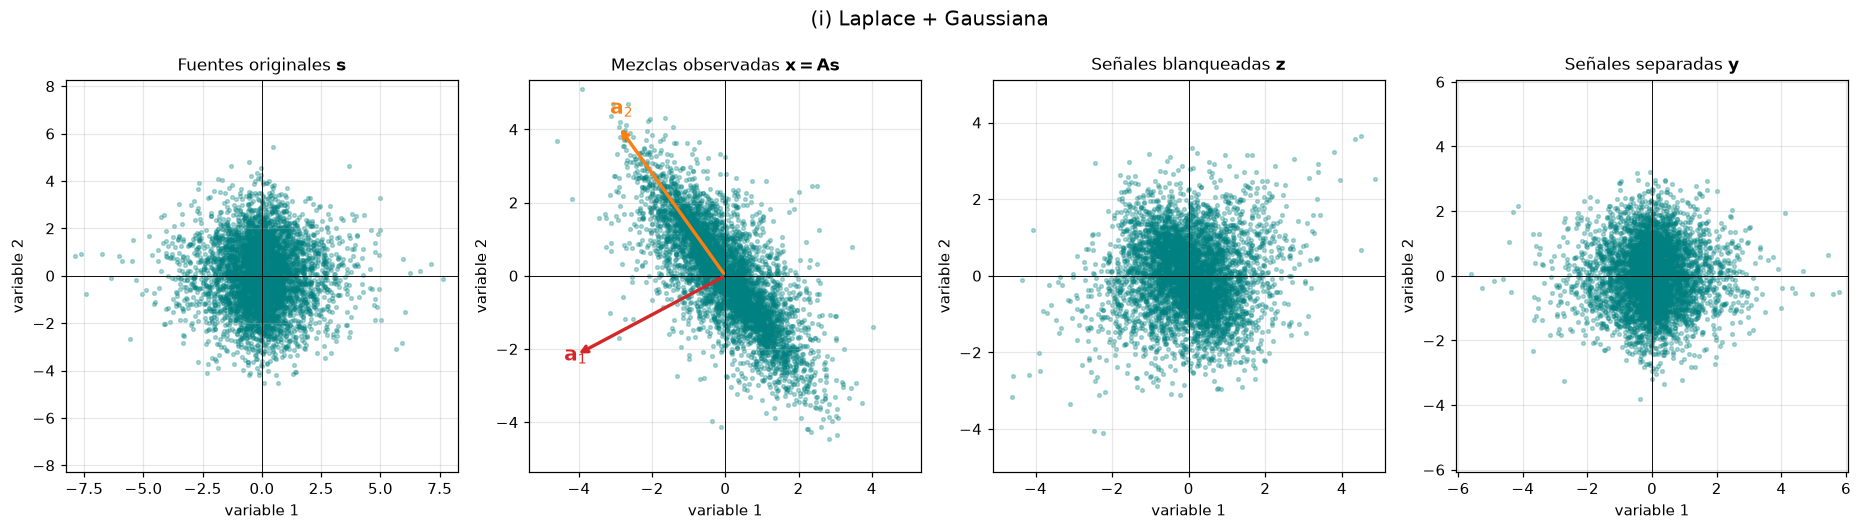

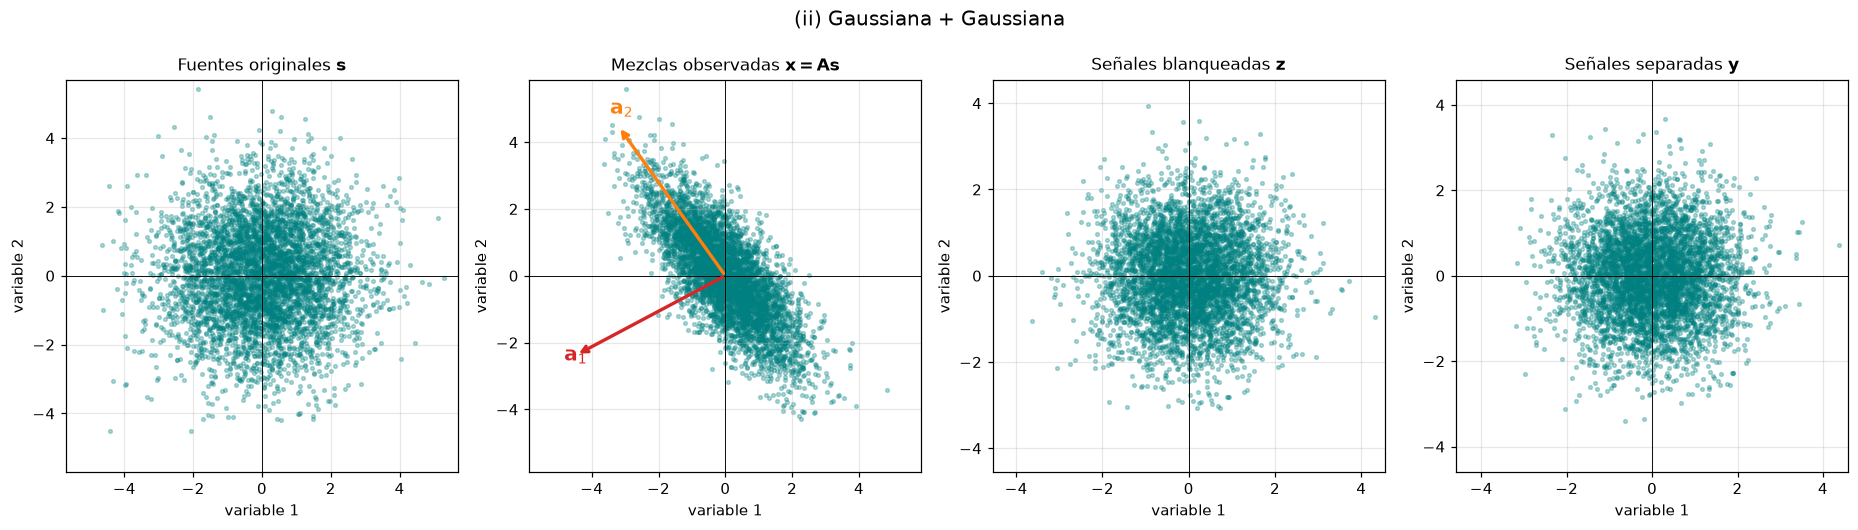

In [16]:
def fuentes_mixtas(tipos, N, rng):
    '''tipos: lista con "laplace" o "gauss" por fuente. Todas con varianza 2.'''
    filas = [rng.laplace(0, 1, N) if t == "laplace" else rng.normal(0, np.sqrt(2), N) for t in tipos]
    return np.vstack(filas)


escenarios = {"Referencia: Laplace + Laplace": ["laplace", "laplace"],
              "(i) Laplace + Gaussiana": ["laplace", "gauss"],
              "(ii) Gaussiana + Gaussiana": ["gauss", "gauss"]}

# Una realización de cada escenario, con la misma matriz A, para graficar las etapas
datos_esc = {}
for nombre, tipos in escenarios.items():
    r_ = np.random.default_rng(11)
    S_ = fuentes_mixtas(tipos, N, r_)
    res = ica(A @ S_, r_)
    datos_esc[nombre] = (S_, res)
    graficar_etapas(S_, A @ S_, res["Xw"], res["Y"], A, titulo=nombre)

In [17]:
# Desempeño medio (40 repeticiones) y curtosis de las salidas
print(f"{'Escenario':<32} | {'Amari (media ± desvío)':>23} | {'|corr| media ± desvío':>22} | Amari solo blanq.")
rng_e = np.random.default_rng(21)
resumen_esc = {}
for nombre, tipos in escenarios.items():
    gen = lambda rng_, t=tipos: (fuentes_mixtas(t, N, rng_), A)
    am, co, base = experimento(gen, 0.0, 40, rng_e)
    resumen_esc[nombre] = (am, co, base)
    print(f"{nombre:<32} | {am.mean():11.4f} ± {am.std():.4f}   | {co.mean():12.4f} ± {co.std():.4f} | {base.mean():.4f}")

# Referencia: Amari esperado si W_ica fuera una rotación elegida al azar (lo que "hace" ICA con fuentes gaussianas)
th = np.random.default_rng(0).uniform(0, 2 * np.pi, 20_000)
amari_azar = np.mean([indice_amari(np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])) for t in th])
print(f"\nAmari esperado para una rotación al azar (referencia): {amari_azar:.4f}  (= 2 ln2 / π ≈ {2 * np.log(2) / np.pi:.4f})")

Escenario                        |  Amari (media ± desvío) |  |corr| media ± desvío | Amari solo blanq.
Referencia: Laplace + Laplace    |      0.0193 ± 0.0166   |       0.9997 ± 0.0005 | 0.6625
(i) Laplace + Gaussiana          |      0.0173 ± 0.0112   |       0.9998 ± 0.0003 | 0.6619


(ii) Gaussiana + Gaussiana       |      0.5211 ± 0.2661   |       0.8757 ± 0.0851 | 0.6636



Amari esperado para una rotación al azar (referencia): 0.4409  (= 2 ln2 / π ≈ 0.4413)


#### Caso (ii): la solución depende de la inicialización

Si ambas fuentes son gaussianas, FastICA no tiene dónde "anclarse": se repite la separación sobre **los mismos datos** cambiando la semilla de inicialización. Se muestra el ángulo de rotación elegido para $\mathbf{W}_{ica}$ y la matriz global $\mathbf{G}=\mathbf{W}\mathbf{A}$.

In [18]:
S_g, _ = datos_esc["(ii) Gaussiana + Gaussiana"]
X_g = A @ S_g

print(f"{'corrida':>7} | {'ángulo de w1 (°)':>16} | {'iteraciones':>12} | {'convergió':>9} | {'Amari':>6} | G = W A (filas)")
for k in range(6):
    r = ica(X_g, np.random.default_rng(200 + k))
    Gk = r["W"] @ A
    ang = np.degrees(np.arctan2(r["W_ica"][0, 1], r["W_ica"][0, 0]))
    print(f"{k + 1:>7} | {ang:16.1f} | {str(r['n_iter']):>12} | {str(all(r['convergio'])):>9} | {indice_amari(Gk):6.3f} | "
          f"{np.array2string(Gk.round(2), separator=',').replace(chr(10), ' ')}")

print("\nPara comparar, con fuentes laplacianas G es siempre una permutación escalada (ver tabla de la sección 2.4).")

corrida | ángulo de w1 (°) |  iteraciones | convergió |  Amari | G = W A (filas)
      1 |            -69.4 |      [81, 2] |      True |  0.224 | [[ 0.16,-0.69],  [-0.69,-0.15]]
      2 |            -21.8 |      [65, 2] |      True |  0.699 | [[-0.4 ,-0.57],  [ 0.58,-0.41]]
      3 |            -21.8 |      [22, 2] |      True |  0.699 | [[-0.4 ,-0.57],  [ 0.58,-0.41]]
      4 |             41.2 |       [5, 2] |      True |  0.139 | [[-0.7 , 0.1 ],  [ 0.09, 0.7 ]]
      5 |             41.1 |       [8, 2] |      True |  0.139 | [[-0.7 , 0.1 ],  [-0.09,-0.7 ]]
      6 |            110.7 |      [87, 2] |      True |  0.222 | [[-0.16, 0.69],  [-0.69,-0.15]]

Para comparar, con fuentes laplacianas G es siempre una permutación escalada (ver tabla de la sección 2.4).


**Observaciones.**

- **(i) Una fuente gaussiana.** FastICA **separa igual de bien** que en el caso de referencia (Amari $0.017$ vs. $0.019$; correlación $\approx0.9998$). El modelo es identificable porque la fuente laplaciana se detecta por su no gaussianidad y la gaussiana es el complemento ortogonal; recién con dos o más gaussianas se pierde la identificabilidad.
- **(ii) Dos fuentes gaussianas.** La separación **falla**: el índice de Amari medio es $0.52\pm0.27$, del orden del valor que se obtendría con una rotación elegida al azar ($0.44$), y la matriz $\mathbf{G}=\mathbf{W}\mathbf{A}$ no es una permutación escalada. En los gráficos las cuatro etapas son nubes elípticas o circulares sin estructura: tras el blanqueado la nube es una gaussiana esférica, invariante a rotaciones, y la salida de FastICA es otra nube esférica indistinguible de la blanqueada.
- **El resultado depende de la inicialización y de la muestra.** Con los mismos datos, distintas inicializaciones llevan a rotaciones distintas ($-69^\circ$, $-22^\circ$, $41^\circ$, $111^\circ$), con Amari entre $0.14$ y $0.70$. Algunas corridas quedan "cerca" de la solución correcta ($0.14$) por pura casualidad. Todas las corridas reportan convergencia, pero se interpreta que lo hacen en máximos *locales de la muestra* del contraste (pequeñas desviaciones aleatorias de la gaussianidad), que no reflejan ninguna estructura real y cambiarían con otra muestra. Además, la primera componente tarda mucho más en algunas corridas (65, 81 y 87 iteraciones frente a 5 u 8 en otras), señal de que el contraste es casi plano.
- **Cuidado con la correlación como métrica.** En 2D, una rotación cualquiera nunca da una correlación absoluta menor que $\cos45^\circ\approx0.71$ con la asignación óptima, por eso la correlación media del caso (ii) ($0.88$) parece aceptable aunque la separación sea aleatoria. El índice de Amari es la medida adecuada aquí.
- **Relación con el inciso d).** Una componente de ruido gaussiano actúa como una fuente gaussiana adicional: la parte gaussiana del modelo no es identificable por no gaussianidad, y por eso degrada la separación.

---
## 3. Conclusiones

1. **FastICA deflacionario.** Tras centrar y blanquear los datos, el problema se reduce a hallar una rotación. Se buscan, una a una, las direcciones que maximizan la no gaussianidad ($\log\cosh$) con la iteración de punto fijo $\mathbf{w}\leftarrow E\{\mathbf{z}\,g(\mathbf{w}^\top\mathbf{z})\}-E\{g'(\mathbf{w}^\top\mathbf{z})\}\mathbf{w}$ y ortogonalizando respecto de las anteriores. Converge en pocas iteraciones y coincide con `scikit-learn`.
2. **Etapas de la separación.** Las mezclas se vuelven más gaussianas que las fuentes (TLC, curtosis); el blanqueado fija los estadísticos de segundo orden pero deja una rotación sin determinar, que solo se puede hallar con estadísticos de orden superior. Las señales separadas recuperan la estructura (y la curtosis) de las fuentes.
3. **Ambigüedades.** $\mathbf{W}$ no es $\mathbf{A}^{-1}$ sino $\mathbf{W}=\mathbf{P}\mathbf{D}\mathbf{A}^{-1}$: las fuentes se recuperan salvo **orden** ($\mathbf{P}$), **signo y escala** ($\mathbf{D}$, aquí $|D_{jj}|=1/\sigma_{s_j}\approx0.707$). El orden y el signo cambian entre corridas sin afectar la calidad de la separación.
4. **Ruido gaussiano aditivo.** Rompe el modelo: $\mathbf{W}$ queda sesgada y deja de valer $\mathbf{P}\mathbf{D}\mathbf{A}^{-1}$. La dirección de separación es robusta a ruido moderado, pero las señales recuperadas quedan contaminadas por $\mathbf{W}\mathbf{n}$, lo que limita la calidad incluso con un separador perfecto (más aún si $\mathbf{A}$ está mal condicionada).
5. **Fuentes gaussianas.** Con **una** fuente gaussiana ICA sigue funcionando; con **dos** (o más) el modelo no es identificable: tras el blanqueado la nube es esférica, cualquier rotación es equivalente, y el resultado depende de la inicialización y de la muestra. ICA necesita fuentes no gaussianas.